# 3장 1강 프로젝트 개요와 문제 정의

## 실습 목표

- Ravenstack의 5개 테이블을 탐색하고 분석 단위와 연결 키를 설명한다.
- 데이터 품질과 기초 분포를 확인하여 분석 가능한 근거를 만든다.
- EDA 결과를 바탕으로 측정 가능한 문제, 목표 지표, 초기 가설을 정의한다.
- 이후 강의에서 검증할 분석 흐름을 일관되게 설계한다.

## 실습 환경 / 데이터

- Python / Colab, `pandas`, `matplotlib`
- `ravenstack_accounts.csv`: 계정 속성과 계정 이탈 여부
- `ravenstack_subscriptions.csv`: 구독 이력과 MRR, 플랜, 이탈 여부
- `ravenstack_feature_usage.csv`: 기능별 사용량과 오류
- `ravenstack_support_tickets.csv`: 문의 처리와 만족도
- `ravenstack_churn_events.csv`: 이탈 사유와 환불

> 분석 기준: 계정의 대표 이탈 지표는 `accounts.churn_flag`로 정의합니다. 서로 다른 테이블의 같은 이름 컬럼을 임의로 섞지 않습니다.

## 실습 준비

**파일 구분: 정답 및 해설**

### 데이터 불러오기

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.style.use("seaborn-v0_8-whitegrid")

file_names = {
    "accounts": "ravenstack_accounts.csv",
    "subscriptions": "ravenstack_subscriptions.csv",
    "feature_usage": "ravenstack_feature_usage.csv",
    "support_tickets": "ravenstack_support_tickets.csv",
    "churn_events": "ravenstack_churn_events.csv",
}
required = ["accounts", "subscriptions", "feature_usage", "support_tickets"]  # churn_events는 선택

candidate_dirs = [Path("."), Path("upload"), Path("/content")]
data_dir = next((d for d in candidate_dirs if all((d / file_names[n]).exists() for n in required)), None)
if data_dir is None:
    raise FileNotFoundError("CSV를 노트북과 같은 폴더(또는 /content)에 업로드해 주세요.")

data = {name: pd.read_csv(data_dir / file) for name, file in file_names.items() if (data_dir / file).exists()}
missing = [n for n in file_names if n not in data]
accounts = data["accounts"]
subscriptions = data["subscriptions"]
feature_usage = data["feature_usage"]
support_tickets = data["support_tickets"]
churn_events = data.get("churn_events")  # 파일이 없으면 None

print("데이터 폴더:", data_dir.resolve())
for name, df in data.items():
    print(f"{name:16s}: {df.shape[0]:,}행 × {df.shape[1]}열")
if missing:
    print("⚠ 업로드되지 않은 파일:", missing, "→ 해당 테이블은 이번 실행에서 제외됩니다.")

데이터 폴더: /home/claude/w
accounts        : 500행 × 10열
subscriptions   : 5,000행 × 14열
feature_usage   : 25,000행 × 8열
support_tickets : 2,000행 × 9열
⚠ 업로드되지 않은 파일: ['churn_events'] → 해당 테이블은 이번 실행에서 제외됩니다.


### 분석 대상 컬럼 확인

각 테이블의 앞부분과 컬럼을 확인하세요.

In [2]:
for name, df in data.items():
    print(f"\n[{name}] 컬럼")
    print(df.columns.tolist())
    display(df.head(2))


[accounts] 컬럼
['account_id', 'account_name', 'industry', 'country', 'signup_date', 'referral_source', 'plan_tier', 'seats', 'is_trial', 'churn_flag']


,account_id,account_name,industry,country,signup_date,referral_source,plan_tier,seats,is_trial,churn_flag
0,A-2e4581,Company_0,EdTech,US,2024-10-16,partner,Basic,9,False,False
1,A-43a9e3,Company_1,FinTech,IN,2023-08-17,other,Basic,18,False,True



[subscriptions] 컬럼
['subscription_id', 'account_id', 'start_date', 'end_date', 'plan_tier', 'seats', 'mrr_amount', 'arr_amount', 'is_trial', 'upgrade_flag', 'downgrade_flag', 'churn_flag', 'billing_frequency', 'auto_renew_flag']


,subscription_id,account_id,start_date,end_date,plan_tier,seats,mrr_amount,arr_amount,is_trial,upgrade_flag,downgrade_flag,churn_flag,billing_frequency,auto_renew_flag
0,S-8cec59,A-3c1a3f,2023-12-23,2024-04-12,Enterprise,14,2786,33432,False,False,False,True,monthly,True
1,S-0f6f44,A-9b9fe9,2024-06-11,NaN,Pro,17,833,9996,False,False,False,False,monthly,True



[feature_usage] 컬럼
['usage_id', 'subscription_id', 'usage_date', 'feature_name', 'usage_count', 'usage_duration_secs', 'error_count', 'is_beta_feature']


,usage_id,subscription_id,usage_date,feature_name,usage_count,usage_duration_secs,error_count,is_beta_feature
0,U-1c6c24,S-0fcf7d,2023-07-27,feature_20,9,5004,0,False
1,U-f07cb8,S-c25263,2023-08-07,feature_5,9,369,0,False



[support_tickets] 컬럼
['ticket_id', 'account_id', 'submitted_at', 'closed_at', 'resolution_time_hours', 'priority', 'first_response_time_minutes', 'satisfaction_score', 'escalation_flag']


,ticket_id,account_id,submitted_at,closed_at,resolution_time_hours,priority,first_response_time_minutes,satisfaction_score,escalation_flag
0,T-0024de,A-712f1c,2023-07-27,2023-07-28 03:00:00,27.0,high,74,NaN,False
1,T-4d04b9,A-e43bf7,2024-07-08,2024-07-09 03:00:00,27.0,urgent,144,NaN,False


### 결측치 및 자료형 확인

날짜 컬럼을 변환하고 키 중복을 확인합니다.

In [3]:
# 날짜 컬럼을 datetime으로 변환합니다.
date_columns = {
    "accounts": ["signup_date"],
    "subscriptions": ["start_date", "end_date"],
    "feature_usage": ["usage_date"],
    "support_tickets": ["submitted_at", "closed_at"],
    "churn_events": ["churn_date"],
}
for name, columns in date_columns.items():
    if name not in data:
        continue
    for column in columns:
        data[name][column] = pd.to_datetime(data[name][column], errors="coerce")

# 분석 단위와 키를 확인합니다.
key_columns = {
    "accounts": "account_id",
    "subscriptions": "subscription_id",
    "feature_usage": "usage_id",
    "support_tickets": "ticket_id",
    "churn_events": "churn_event_id",
}
for name, key in key_columns.items():
    if name not in data:
        continue
    df = data[name]
    print(f"{name:16s} | key 중복 {df[key].duplicated().sum():>2} | 전체 행 중복 {df.duplicated().sum():>2}")

accounts         | key 중복  0 | 전체 행 중복  0
subscriptions    | key 중복  0 | 전체 행 중복  0
feature_usage    | key 중복 21 | 전체 행 중복  0
support_tickets  | key 중복  0 | 전체 행 중복  0


### 기초 통계량과 분포 확인

아래 코드로 수치형 변수와 주요 범주의 분포를 확인하세요.

In [4]:
display(accounts[["seats", "churn_flag"]].describe())
display(accounts["plan_tier"].value_counts().rename("accounts"))
if churn_events is not None:
    display(churn_events["reason_code"].value_counts().rename("events"))
else:
    print("churn_events 미업로드 → reason_code 분포는 건너뜁니다.")

,seats
count,500.000000
mean,20.560000
std,21.044718
min,1.000000
25%,5.000000
50%,15.000000
75%,28.000000
max,163.000000


plan_tier
Pro           178
Basic         168
Enterprise    154
Name: accounts, dtype: int64

churn_events 미업로드 → reason_code 분포는 건너뜁니다.


---

## 필수 1 — 5개 테이블의 EDA 요약

각 테이블에 대해 다음 항목을 하나의 요약표로 만드세요.

1. 행 수와 열 수
2. 전체 결측치 수
3. 완전히 동일한 중복 행 수
4. 날짜 범위(최솟값~최댓값)

그 후 다음 질문에 답하세요.

- 결측치가 있는 테이블과 컬럼은 무엇인가요?
- 결측치를 곧바로 삭제하면 안 되는 이유는 무엇인가요?
- 분석 전에 주의할 데이터 품질 문제를 한 가지 쓰세요.

In [5]:
summary_rows = []
for name, df in data.items():
    dates = date_columns.get(name, [])
    date_min = min(df[c].min() for c in dates)
    date_max = max(df[c].max() for c in dates)
    na = df.isna().sum()
    summary_rows.append({
        "table": name,
        "rows": df.shape[0],
        "cols": df.shape[1],
        "missing_total": int(na.sum()),
        "missing_columns": ", ".join(f"{c}({n})" for c, n in na[na > 0].items()) or "-",
        "duplicate_rows": int(df.duplicated().sum()),
        "key_duplicates": int(df[key_columns[name]].duplicated().sum()),
        "date_range": f"{date_min:%Y-%m-%d} ~ {date_max:%Y-%m-%d}",
    })

eda_summary = pd.DataFrame(summary_rows)
display(eda_summary)

,table,rows,cols,missing_total,missing_columns,duplicate_rows,key_duplicates,date_range
0,accounts,500,10,0,-,0,0,2023-01-02 ~ 2024-12-31
1,subscriptions,5000,14,4514,end_date(4514),0,0,2023-01-09 ~ 2024-12-31
2,feature_usage,25000,8,0,-,0,21,2023-01-01 ~ 2024-12-31
3,support_tickets,2000,9,825,satisfaction_score(825),0,0,2023-01-02 ~ 2024-12-31


### 필수 1 · 추가 점검 — 결측의 의미와 품질 이슈 확인

In [6]:
# 1) subscriptions.end_date 결측은 '아직 종료되지 않은 구독'인가?
print("[subscriptions] churn_flag × end_date 존재 여부")
display(pd.crosstab(subscriptions["churn_flag"], subscriptions["end_date"].notna(),
                    rownames=["sub churn_flag"], colnames=["end_date 있음"]))

# 2) support_tickets.satisfaction_score 결측 비율
sat_na = support_tickets["satisfaction_score"].isna().mean()
print(f"[support_tickets] satisfaction_score 결측 비율: {sat_na:.1%}")

# 3) feature_usage.usage_id 키 중복 — 전체 행은 다른데 id만 같은 경우
dup_ids = feature_usage[feature_usage["usage_id"].duplicated(keep=False)].sort_values("usage_id")
print(f"[feature_usage] usage_id 중복 행 {len(dup_ids)}개 (고유 id {dup_ids['usage_id'].nunique()}개)")
display(dup_ids.head(4))

# 4) 같은 이름 churn_flag의 테이블 간 불일치
acc_flag = accounts.set_index("account_id")["churn_flag"]
sub_any = subscriptions.groupby("account_id")["churn_flag"].any().reindex(acc_flag.index, fill_value=False)
print("[accounts.churn_flag vs 구독 중 하나라도 churn_flag=True]")
display(pd.crosstab(acc_flag, sub_any, rownames=["accounts.churn_flag"], colnames=["subs 중 churn 존재"]))

# 5) 연결 키 무결성(고아 레코드)
print("구독→계정 미매칭:", (~subscriptions["account_id"].isin(accounts["account_id"])).sum(),
      "| 사용→구독 미매칭:", (~feature_usage["subscription_id"].isin(subscriptions["subscription_id"])).sum(),
      "| 티켓→계정 미매칭:", (~support_tickets["account_id"].isin(accounts["account_id"])).sum())

[subscriptions] churn_flag × end_date 존재 여부


end_date 있음,False,True
sub churn_flag,,
False,4514,0
True,0,486


[support_tickets] satisfaction_score 결측 비율: 41.2%
[feature_usage] usage_id 중복 행 42개 (고유 id 21개)


,usage_id,subscription_id,usage_date,feature_name,usage_count,usage_duration_secs,error_count,is_beta_feature
19294,U-0c9318,S-01b2dc,2023-12-11,feature_9,5,1060,3,False
17533,U-0c9318,S-0ffab0,2024-01-30,feature_11,3,1614,0,False
20588,U-13ce5b,S-9b623b,2023-03-26,feature_28,10,2050,1,False
9626,U-13ce5b,S-8b0950,2024-09-10,feature_9,8,824,0,True


[accounts.churn_flag vs 구독 중 하나라도 churn_flag=True]


subs 중 churn 존재,False,True
accounts.churn_flag,,
False,150,240
True,38,72


구독→계정 미매칭: 0 | 사용→구독 미매칭: 0 | 티켓→계정 미매칭: 0


**답안 작성**

- 계산·출력 결과:
  - 업로드된 4개 테이블 모두 **완전 중복 행은 0개**이고, 연결 키(`account_id`, `subscription_id`)로 매칭되지 않는 고아 레코드도 없습니다.
  - 기간은 대체로 **2023-01 ~ 2024-12**(약 2년)입니다.
  - ⚠ `ravenstack_churn_events.csv`는 프로젝트에 업로드되어 있지 않아 이번 실행 결과에서는 빠졌습니다. 파일을 올리고 다시 실행하면 요약표에 한 줄이 추가됩니다.

- **Q1. 결측치가 있는 테이블과 컬럼**
  - `subscriptions.end_date`: 4,514개(전체 5,000개 중 90.3%)
  - `support_tickets.satisfaction_score`: 825개(전체 2,000개 중 41.2%)
  - 나머지 테이블(accounts, feature_usage)에는 결측이 없습니다.

- **Q2. 결측치를 곧바로 삭제하면 안 되는 이유**
  - 결측이 "값이 빠졌다"가 아니라 **의미를 가진 상태**이기 때문입니다.
    - `end_date` 결측은 모두 `churn_flag=False`인 구독과 정확히 일치합니다(4,514 = 4,514). 즉 "**아직 끝나지 않은(활성) 구독**"이라는 뜻입니다. 삭제하면 이탈한 구독 486개만 남아, 이탈률이 100%인 것처럼 왜곡됩니다.
    - `satisfaction_score` 결측은 "고객이 설문에 **응답하지 않음**"일 가능성이 큽니다. 불만이 큰 고객이 응답을 안 했을 수도 있으므로, 삭제하면 만족도가 실제보다 좋게 보일 수 있습니다(응답 편향).
  - 따라서 결측을 지우기 전에 **왜 비어 있는지**를 먼저 확인하고, 필요하면 `is_active`, `survey_responded` 같은 표시 컬럼으로 바꿔 분석에 활용합니다.

- **Q3. 분석 전에 주의할 데이터 품질 문제**
  - **같은 이름의 `churn_flag`가 테이블마다 다른 뜻**입니다.
    - `accounts.churn_flag`는 계정 단위, `subscriptions.churn_flag`는 구독 한 건 단위입니다.
    - 교차표를 보면 계정 이탈 여부와 "구독 중 하나라도 이탈" 여부가 맞지 않는 계정이 많습니다(예: 계정은 이탈이 아닌데 구독 이탈이 있는 경우 240개, 계정은 이탈인데 이탈 구독이 없는 경우 38개).
    - 그래서 이번 프로젝트에서는 실습 안내대로 **`accounts.churn_flag` 하나만** 대표 이탈 지표로 쓰고, 두 컬럼을 섞지 않습니다.
  - (추가) `feature_usage.usage_id`에 **키 중복 21건**이 있습니다. 전체 행이 같은 것은 아니므로 단순 중복 삭제 대상은 아닙니다. id 생성 오류일 가능성이 있어, 사용량을 합칠 때는 `usage_id`를 고유 키로 믿지 말고 행 단위로 집계합니다.

---

## 필수 2 — 근거를 연결해 분석 문제 정의하기

계정 테이블을 기준으로 다음을 분석하세요.

1. 전체 계정 이탈률을 계산하세요.
2. `industry`, `referral_source`, `is_trial`별 계정 수와 이탈률을 계산하세요.
3. 표본이 20개 이상인 세그먼트 중 전체 이탈률보다 높은 구간을 찾으세요.
4. 결과를 근거로 **문제 정의 1문장**, **현재 지표**, **목표 지표**를 작성하세요.
5. 이탈률이 가장 높은 산업군을 막대그래프로 비교하세요.

> 목표값은 정답이 하나가 아닙니다. 현재 값보다 개선된 수치이며, 지표·대상·기간(또는 평가 시점)이 드러나게 작성하세요.

In [7]:
overall_churn_rate = accounts["churn_flag"].mean()
print(f"전체 계정 수: {len(accounts)}개 / 이탈 계정: {accounts['churn_flag'].sum()}개 / 전체 이탈률: {overall_churn_rate:.1%}")

MIN_N = 20
segment_results = {}
for column in ["industry", "referral_source", "is_trial"]:
    seg = (accounts.groupby(column)["churn_flag"]
           .agg(accounts="size", churned="sum", churn_rate="mean")
           .sort_values("churn_rate", ascending=False))
    seg["diff_vs_overall(%p)"] = (seg["churn_rate"] - overall_churn_rate) * 100
    segment_results[column] = seg
    print(f"\n[{column}]")
    display(seg.style.format({"churn_rate": "{:.1%}", "diff_vs_overall(%p)": "{:+.1f}"}))

# 표본 20개 이상 & 전체보다 높은 구간
high_risk = pd.concat(
    [seg.assign(segment=col).reset_index().rename(columns={col: "value"})
     for col, seg in segment_results.items()]
)
high_risk = high_risk[(high_risk["accounts"] >= MIN_N) & (high_risk["churn_rate"] > overall_churn_rate)]
high_risk = high_risk.sort_values("churn_rate", ascending=False)[
    ["segment", "value", "accounts", "churned", "churn_rate", "diff_vs_overall(%p)"]]
print(f"\n표본 {MIN_N}개 이상 & 전체 이탈률({overall_churn_rate:.1%})보다 높은 세그먼트")
display(high_risk.style.format({"churn_rate": "{:.1%}", "diff_vs_overall(%p)": "{:+.1f}"}))

전체 계정 수: 500개 / 이탈 계정: 110개 / 전체 이탈률: 22.0%

[industry]


,accounts,churned,churn_rate,diff_vs_overall(%p)
industry,,,,
DevTools,113,35,31.0%,+9.0
FinTech,112,25,22.3%,+0.3
HealthTech,96,21,21.9%,-0.1
EdTech,79,13,16.5%,-5.5
Cybersecurity,100,16,16.0%,-6.0



[referral_source]


,accounts,churned,churn_rate,diff_vs_overall(%p)
referral_source,,,,
event,96,29,30.2%,+8.2
other,103,25,24.3%,+2.3
ads,98,23,23.5%,+1.5
organic,114,20,17.5%,-4.5
partner,89,13,14.6%,-7.4



[is_trial]


,accounts,churned,churn_rate,diff_vs_overall(%p)
is_trial,,,,
True,97,25,25.8%,+3.8
False,403,85,21.1%,-0.9



표본 20개 이상 & 전체 이탈률(22.0%)보다 높은 세그먼트


,segment,value,accounts,churned,churn_rate,diff_vs_overall(%p)
0,industry,DevTools,113,35,31.0%,+9.0
0,referral_source,event,96,29,30.2%,+8.2
0,is_trial,True,97,25,25.8%,+3.8
1,referral_source,other,103,25,24.3%,+2.3
2,referral_source,ads,98,23,23.5%,+1.5
1,industry,FinTech,112,25,22.3%,+0.3


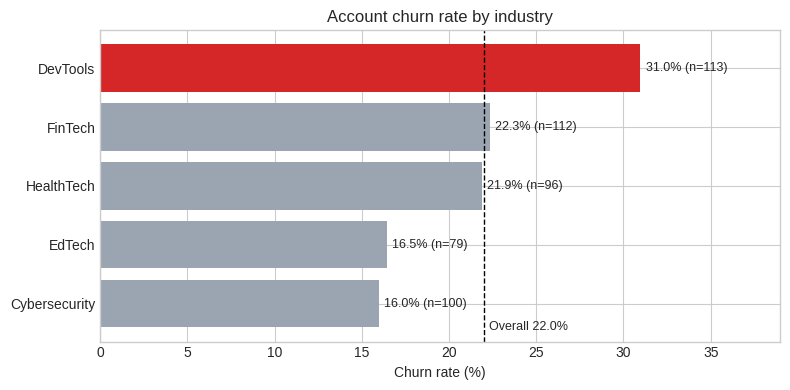

In [8]:
ind = segment_results["industry"].sort_values("churn_rate")
top = ind["churn_rate"].idxmax()
colors = ["#d62728" if i == top else "#9aa5b1" for i in ind.index]

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(ind.index, ind["churn_rate"] * 100, color=colors)
ax.axvline(overall_churn_rate * 100, color="black", ls="--", lw=1)
ax.text(overall_churn_rate * 100 + 0.3, -0.45, f"Overall {overall_churn_rate:.1%}", fontsize=9)
for b, (rate, n) in zip(bars, zip(ind["churn_rate"], ind["accounts"])):
    ax.text(b.get_width() + 0.3, b.get_y() + b.get_height() / 2, f"{rate:.1%} (n={n})", va="center", fontsize=9)
ax.set_title("Account churn rate by industry")
ax.set_xlabel("Churn rate (%)")
ax.set_xlim(0, ind["churn_rate"].max() * 100 + 8)
plt.tight_layout()
plt.show()

### 필수 2 · 추가 확인 — 최고 위험 산업(DevTools) 안에서 유입 경로 비교

In [9]:
# 문제를 더 좁힐 수 있는지 확인합니다. (셀 표본이 작으므로 참고용)
devtools = accounts[accounts["industry"] == "DevTools"]
display(devtools.groupby("referral_source")["churn_flag"]
        .agg(accounts="size", churn_rate="mean")
        .sort_values("churn_rate", ascending=False)
        .style.format({"churn_rate": "{:.1%}"}))

,accounts,churn_rate
referral_source,,
event,23,43.5%
ads,26,38.5%
other,24,29.2%
organic,24,25.0%
partner,16,12.5%


### 필수 2 서술 답안

- **발견한 핵심 패턴**
  - 전체 계정 이탈률은 **22.0%**(500개 중 110개)입니다.
  - 표본 20개 이상이면서 전체보다 높은 구간은 다음과 같습니다.

| 기준 | 구간 | 계정 수 | 이탈률 | 전체 대비 |
|---|---|---:|---:|---:|
| industry | **DevTools** | 113 | **31.0%** | **+9.0%p** |
| referral_source | **event** | 96 | **30.2%** | **+8.2%p** |
| is_trial | True | 97 | 25.8% | +3.8%p |
| referral_source | other | 103 | 24.3% | +2.3%p |
| referral_source | ads | 98 | 23.5% | +1.5%p |
| industry | FinTech | 112 | 22.3% | +0.3%p |

  - 차이가 뚜렷한 곳은 **DevTools 산업**과 **event 유입** 두 곳입니다. FinTech(+0.3%p)·ads(+1.5%p)는 전체와 거의 같아서 의미 있는 차이로 보기 어렵습니다.
  - DevTools는 계정 수도 가장 많고(113개), 이탈 계정 35개로 **전체 이탈 110개 중 약 32%** 를 차지합니다. 그래서 우선 개선 대상으로 고릅니다.
  - 참고로 DevTools 안에서는 event(43.5%, n=23)·ads(38.5%, n=26) 유입 계정의 이탈률이 더 높았습니다. 다만 셀당 표본이 20여 개라 이번에는 문제 정의가 아닌 **후속 확인 대상**으로만 둡니다.

- **문제 정의**: "**DevTools 산업 계정의 이탈률(31.0%)이 전체 계정 평균(22.0%)보다 약 9%p 높아, 전체 이탈 계정의 약 3분의 1이 이 산업에서 발생하고 있다.**"
  - 이 문장은 **관찰한 사실**입니다. 왜 이탈하는지(원인)는 아직 모르므로 과제 1에서 가설로 따로 세웁니다.

- **현재 지표**: DevTools 계정 이탈률 = `accounts.churn_flag=True`인 DevTools 계정 수 ÷ 전체 DevTools 계정 수 = **31.0%**(35/113), 관측 기간 2023-01 ~ 2024-12 기준

- **목표 지표**: "**다음 2개 분기(6개월) 동안 새로 가입하거나 갱신 시점이 오는 DevTools 계정의 이탈률을 31.0% → 25% 이하로 낮춘다**"
  - 지표: 계정 이탈률(`accounts.churn_flag`) / 대상: DevTools 산업 계정 / 기간: 향후 6개월, 분기마다 점검
  - 가드레일: 전체 계정 이탈률 22.0%가 나빠지지 않을 것

- **목표 지표가 적절한 이유**
  - 문제 정의와 **같은 지표·같은 대상**을 써서, 개선 여부를 바로 비교할 수 있습니다.
  - 25%는 전체 평균(22%)보다 여전히 높지만 현재보다 **6%p 개선**된 값입니다. 한 번에 평균까지 맞추기보다 6개월 안에 달성할 수 있는 수준으로 잡았습니다.
  - DevTools 이탈 계정은 35개입니다. 이탈률이 25%로 내려가면 약 7개 계정의 이탈을 막는 셈이라, 전체 이탈률도 약 1.4%p 함께 내려갑니다.
  - 계정 수가 113개로 작아서 한두 개 계정만 바뀌어도 비율이 1%p 가까이 움직입니다. 그래서 월 단위가 아니라 **분기 단위**로 보고, 전체 이탈률을 가드레일로 같이 봅니다.

---

## 과제 1 — 이탈 원인 가설과 검증 계획 세우기

필수 2에서 정의한 문제를 바탕으로 초기 가설 3개를 작성하세요.

- 적어도 2개는 현재 제공된 데이터로 검증 가능해야 합니다.
- 각 가설에 `필요한 테이블·컬럼`, `확인할 비교 또는 지표`, `우선순위`를 적으세요.
- 가장 먼저 검증할 가설 1개를 고르고 이유를 설명하세요.
- 2강 분석 → 3강 실험 → 4강 제안이 처음 문제와 어떻게 연결되는지 한 문장씩 작성하세요.

**답안 작성**

필수 2의 문제: "DevTools 계정의 이탈률(31.0%)이 전체(22.0%)보다 약 9%p 높다."

| 우선순위 | 가설 | 필요한 데이터 | 검증 방법 |
|---:|---|---|---|
| 1 | **DevTools 계정은 기능 사용 중 오류를 더 많이 겪고, 오류 경험이 이탈로 이어진다.** | `feature_usage`(`subscription_id`, `usage_count`, `error_count`, `feature_name`) → `subscriptions`(`subscription_id`, `account_id`) → `accounts`(`industry`, `churn_flag`) | 계정별 오류율(`error_count` 합 ÷ `usage_count` 합)을 계산합니다. ① DevTools vs 다른 산업, ② DevTools 안에서 이탈 vs 유지 계정을 비교합니다. 오류가 많은 기능(`feature_name`)도 확인합니다. |
| 2 | **DevTools 계정은 지원 경험이 나쁘다(해결 시간이 길고 에스컬레이션이 많다). 이 경험이 이탈로 이어진다.** | `support_tickets`(`account_id`, `resolution_time_hours`, `first_response_time_minutes`, `escalation_flag`, `satisfaction_score`, `priority`) → `accounts`(`industry`, `churn_flag`) | 계정별 평균 해결 시간, 첫 응답 시간, 에스컬레이션 비율, 티켓 수를 계산해 이탈 vs 유지 계정을 비교합니다. `satisfaction_score`는 41%가 결측이므로 응답한 티켓만 따로 보고, 응답률도 함께 비교합니다. |
| 3 | **event·ads로 유입된 DevTools 계정은 제품 적합도가 낮은 상태로 가입해서, 초기에 제품을 충분히 쓰지 않고 이탈한다.** | `accounts`(`referral_source`, `signup_date`, `industry`, `churn_flag`), `subscriptions`(`start_date`, `is_trial`), `feature_usage`(`usage_date`, `usage_count`) | 가입 후 첫 30일의 사용량과 사용 기능 수를 유입 경로별로 비교합니다. 유입 경로 × 가입 월 코호트로 이탈률을 확인합니다. 현재 데이터로 검증할 수 있지만, 셀 표본이 20여 개라 우선순위를 낮췄습니다. |

- **적어도 2개는 현재 데이터로 검증 가능한가?** 3개 모두 제공된 4개 테이블로 검증할 수 있습니다. 이탈 **사유**(`churn_events.reason_code`)가 업로드되면, 이탈한 DevTools 계정이 "기능 문제 / 지원 / 가격" 중 무엇을 사유로 적었는지도 교차 확인할 수 있습니다.

- **가장 먼저 검증할 가설: 1번(기능 오류)**
  - 데이터가 가장 많습니다. `feature_usage` 25,000행에 오류 수가 **결측 없이** 기록되어 있습니다. 반면 2번의 만족도는 41%가 결측입니다.
  - 제품팀이 바로 **고칠 수 있는 원인**입니다. 특정 기능의 오류가 원인이면 개선안(버그 수정, 안정화, 오류 안내)으로 곧바로 이어져 3강 실험으로 연결하기 쉽습니다.
  - DevTools 고객은 개발자 도구를 다루는 조직이라, 제품 안정성에 민감할 것이라는 도메인 추론도 있습니다. 다만 이것은 **가설**이며, 데이터로 확인하기 전까지 원인으로 단정하지 않습니다.
  - 주의: 오류와 이탈이 같이 나타나도 **상관관계**일 뿐입니다. 사용량이 많은 계정일수록 오류도 많이 겪을 수 있으므로, 오류 **건수**가 아니라 사용량 대비 **오류율**로 비교합니다.

### 프로젝트 연결

- **2강 분석**: DevTools와 다른 산업의 기능 사용·오류율, 그리고 이탈 vs 유지 계정을 Funnel·Segmentation·코호트 리텐션으로 비교합니다. "DevTools가 **어느 기능, 어느 시점**에서 문제를 겪고 이탈하는가"까지 문제를 좁힙니다.
- **3강 실험**: 2강에서 찾은 원인 기능에 대한 개선안(예: 오류가 많은 기능의 안정화, 오류 발생 시 안내·가이드 제공)을 A/B 테스트로 검증합니다. 대상은 DevTools 계정, 목표 지표는 해당 기능 오류율과 **계정 유지율(=1−이탈률)**, 가드레일은 사용량과 지원 티켓 수입니다.
- **4강 제안**: 실험 결과(효과 크기 + 통계적 근거 + 가드레일)를 근거로, 처음 목표인 "**DevTools 이탈률 31.0% → 25% 이하**"를 달성하기 위한 적용 여부와 재측정 계획을 제안합니다.

---

## 실습 마무리

- **어떤 분석 문제가 있었는가?**
  - Ravenstack 전체 계정 이탈률은 22.0%입니다. 이 중 **DevTools 산업 계정의 이탈률이 31.0%로 약 9%p 높아**, 전체 이탈의 약 3분의 1을 차지한다는 문제를 정의했습니다.
- **어떤 통계적·분석적 방법을 적용했는가?**
  - 테이블별 EDA(행·열 수, 결측, 중복, 날짜 범위, 키 무결성)로 데이터를 분석해도 되는지 먼저 확인했습니다.
  - `accounts.churn_flag` 하나를 기준으로 전체 이탈률과 세그먼트별 이탈률(Segmentation)을 계산했습니다.
  - 표본 20개 이상이라는 최소 기준을 둬서, 작은 집단의 우연한 차이를 문제로 고르지 않도록 했습니다.
- **무엇을 근거로 결론을 내렸는가?**
  - 전체 대비 차이(+9.0%p), 계정 수(113개), 전체 이탈 중 비중(35/110)을 함께 보고 우선 대상을 골랐습니다.
  - 이 결론은 **관찰한 사실**입니다. 원인은 과제 1의 가설로 분리해 두었고, 2강 분석 → 3강 실험 → 4강 제안에서 검증합니다.